# Bank Marketing: a CRISP-DM investigation
**Author: SAM**

This analysis answers three business questions using the original UCI `bank-full.csv`. AI assistance was used in implementation and writing; all reported outputs are calculated below. Dataset credit: Moro, Rita and Cortez (2014), DOI 10.24432/C5K306; CC BY 4.0.

## 1. Business understanding
A bank has limited calling capacity. Which prospects merit attention?
1. How does subscription rate differ by previous campaign outcome?
2. How does it differ by number of current-campaign contacts?
3. Can pre-call information rank likely subscribers in a later holdout period?

The target is term-deposit subscription, `y=yes`. Ranking metrics are more informative than accuracy because subscriptions are uncommon. No causal or profitability claim is made.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display, Image
"""Reproduce three marketing questions using the unmodified UCI bank-full data."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

ROOT = Path.cwd()

def load_data():
    """Read the semicolon-delimited full dataset; preserve source row ordering."""
    df = pd.read_csv(ROOT / 'data/bank-full.csv', sep=';')
    assert len(df) == 45211 and set(df.y.unique()) == {'yes', 'no'}
    assert df.duplicated().sum() == 0
    df['subscribed'] = (df.y == 'yes').astype(int)
    return df

def rate_table(df, column):
    """Return sample counts and observed subscription rates by a group."""
    return df.groupby(column, observed=True).subscribed.agg(['count', 'sum', 'mean'])

def fit_model(df):
    """Train only on early rows; exclude call duration and same-campaign outcomes."""
    # Day/month describe the last contact rather than prospect attributes. Exclude
    # them, campaign counts, and duration for a conservative pre-campaign model.
    X = df.drop(columns=['y', 'subscribed', 'duration', 'campaign', 'day', 'month'])
    X = X.replace('unknown', np.nan)
    # -1 means never contacted, not a negative elapsed duration. Preserve that
    # information separately before imputing the elapsed-time value.
    X['previously_contacted'] = (X.pdays != -1).astype(int)
    X['pdays'] = X.pdays.replace(-1, np.nan)
    y = df.subscribed
    split = int(len(df) * .8)
    train_X, test_X, train_y, test_y = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
    categorical = X.select_dtypes(include='object').columns.tolist()
    numeric = X.select_dtypes(exclude='object').columns.tolist()
    prep = ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical)
    ])
    model = Pipeline([('prepare', prep), ('classify', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42))])
    model.fit(train_X, train_y)
    probabilities = model.predict_proba(test_X)[:, 1]
    baseline = DummyClassifier(strategy='most_frequent').fit(train_X, train_y)
    k = int(np.ceil(.2 * len(test_y)))
    selected = np.argsort(probabilities)[-k:]
    metrics = {
        'train_rows': len(train_y), 'test_rows': len(test_y),
        'test_subscription_rate': float(test_y.mean()),
        'roc_auc': float(roc_auc_score(test_y, probabilities)),
        'average_precision': float(average_precision_score(test_y, probabilities)),
        'precision_at_0_5': float(precision_score(test_y, probabilities >= .5)),
        'recall_at_0_5': float(recall_score(test_y, probabilities >= .5)),
        'top_20_percent_rows': k,
        'top_20_percent_subscription_rate': float(test_y.iloc[selected].mean()),
        'top_20_percent_lift': float(test_y.iloc[selected].mean() / test_y.mean()),
        'baseline_accuracy': float(baseline.score(test_X, test_y)),
        'baseline_recall': float(recall_score(test_y, baseline.predict(test_X), zero_division=0)),
        'excluded_columns': ['duration', 'campaign', 'day', 'month']
    }
    return metrics

def run():
    """Write auditable tables, charts and model metrics; return all findings."""
    df = load_data()
    out = ROOT / 'results'
    out.mkdir(exist_ok=True)
    previous = rate_table(df, 'poutcome')
    bands = pd.cut(df.campaign, [0,1,3,5,np.inf], labels=['1','2–3','4–5','6+'])
    campaign = rate_table(df.assign(contact_band=bands), 'contact_band')
    previous.to_csv(out / 'previous_outcome.csv')
    campaign.to_csv(out / 'contact_frequency.csv')
    for table, name, title in [(previous, 'previous_outcome', 'Subscription rate by previous campaign outcome'), (campaign, 'contact_frequency', 'Subscription rate by current campaign contact count')]:
        fig, ax = plt.subplots(figsize=(8,4.6))
        ax.bar(table.index.astype(str), table['mean']*100, color='#146b82')
        ax.set_ylabel('Observed subscription rate (%)')
        ax.set_title(title)
        for i, (_, row) in enumerate(table.iterrows()):
            ax.text(i, row['mean']*100+.5, f"{row['mean']:.1%}\nn={int(row['count']):,}", ha='center', fontsize=9)
        ax.set_ylim(0, table['mean'].max()*100+12)
        fig.tight_layout(); fig.savefig(out / (name+'.png'), dpi=180); plt.close(fig)
    metrics = fit_model(df)
    results = {'rows': len(df), 'subscribers': int(df.subscribed.sum()), 'overall_rate': float(df.subscribed.mean()), 'missing_cells': int(df.isna().sum().sum()), 'unknown_counts': {c:int((df[c]=='unknown').sum()) for c in df.select_dtypes('object')}, 'model':metrics}
    (out / 'metrics.json').write_text(json.dumps(results, indent=2))
    print(json.dumps(results, indent=2))
    return results


df = load_data()
print("Shape:", df.shape)
display(df.head())

Shape: (45211, 18)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,subscribed
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0


## 2. Data understanding
The source file contains 45,211 rows and 16 input fields plus the target, ordered by date. Inputs include customer attributes, last-contact details and prior-campaign information. Audit types, missing values, duplicate rows, special category values and numeric distributions. There are no literal missing cells, but unknown categories and the pdays=-1 sentinel carry missingness semantics.

In [2]:
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all"))
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicates:", int(df.duplicated().sum()))
print("Positive rate:", df.subscribed.mean())
print("Never contacted:", int((df.pdays == -1).sum()))
print({c: int((df[c] == "unknown").sum()) for c in df.select_dtypes("object")})

Missing cells: 0
Duplicates: 0
Positive rate: 0.11698480458295547
Never contacted: 36954
{'job': 288, 'marital': 0, 'education': 1857, 'default': 0, 'housing': 0, 'loan': 0, 'contact': 13020, 'month': 0, 'poutcome': 36959, 'y': 0}


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,subscribed
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211,45211.000000
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2,NaN
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no,NaN
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922,NaN
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN,0.116985
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN,0.321406
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN,0.000000
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN,0.000000
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN,0.000000
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN,0.000000


## 3. Data preparation
Preserve all source rows: dropping unknown outcomes would discard most observations and distort descriptive rates. For descriptive questions, retain unknown as its own group. For modeling, unknown categorical values become missing, pdays=-1 becomes missing elapsed time with a separate previously_contacted flag. Median numeric imputation and most-frequent categorical imputation, scaling and one-hot encoding are fitted only on training rows.

Exclude duration because it is unavailable before the call. Also exclude campaign, day and month because they describe current campaign progression or final contact. The planned contact channel is assumed available at scoring time. Split first 80% for training and last 20% for testing to respect source ordering; do not shuffle. The reusable implementation below shows the full transformations.

In [3]:
import inspect
print(inspect.getsource(fit_model))

def fit_model(df):
    """Train only on early rows; exclude call duration and same-campaign outcomes."""
    # Day/month describe the last contact rather than prospect attributes. Exclude
    # them, campaign counts, and duration for a conservative pre-campaign model.
    X = df.drop(columns=['y', 'subscribed', 'duration', 'campaign', 'day', 'month'])
    X = X.replace('unknown', np.nan)
    # -1 means never contacted, not a negative elapsed duration. Preserve that
    # information separately before imputing the elapsed-time value.
    X['previously_contacted'] = (X.pdays != -1).astype(int)
    X['pdays'] = X.pdays.replace(-1, np.nan)
    y = df.subscribed
    split = int(len(df) * .8)
    train_X, test_X, train_y, test_y = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
    categorical = X.select_dtypes(include='object').columns.tolist()
    numeric = X.select_dtypes(exclude='object').columns.tolist()
    prep = ColumnTransformer([
        ('numeric', Pipeline([('imput

## 4. Analysis: question 1
Does prior campaign success identify a high-conversion group? Rates are descriptive, and prior success is a small segment rather than evidence of a causal treatment effect.

{
  "rows": 45211,
  "subscribers": 5289,
  "overall_rate": 0.11698480458295547,
  "missing_cells": 0,
  "unknown_counts": {
    "job": 288,
    "marital": 0,
    "education": 1857,
    "default": 0,
    "housing": 0,
    "loan": 0,
    "contact": 13020,
    "month": 0,
    "poutcome": 36959,
    "y": 0
  },
  "model": {
    "train_rows": 36168,
    "test_rows": 9043,
    "test_subscription_rate": 0.31582439455932765,
    "roc_auc": 0.7162256045136658,
    "average_precision": 0.5467474629893788,
    "precision_at_0_5": 0.42482283087531125,
    "recall_at_0_5": 0.7766106442577031,
    "top_20_percent_rows": 1809,
    "top_20_percent_subscription_rate": 0.6086235489220564,
    "top_20_percent_lift": 1.9270948014363292,
    "baseline_accuracy": 0.6841756054406724,
    "baseline_recall": 0.0,
    "excluded_columns": [
      "duration",
      "campaign",
      "day",
      "month"
    ]
  }
}


,count,sum,mean
poutcome,,,
failure,4901,618,0.126097
other,1840,307,0.166848
success,1511,978,0.647253
unknown,36959,3386,0.091615


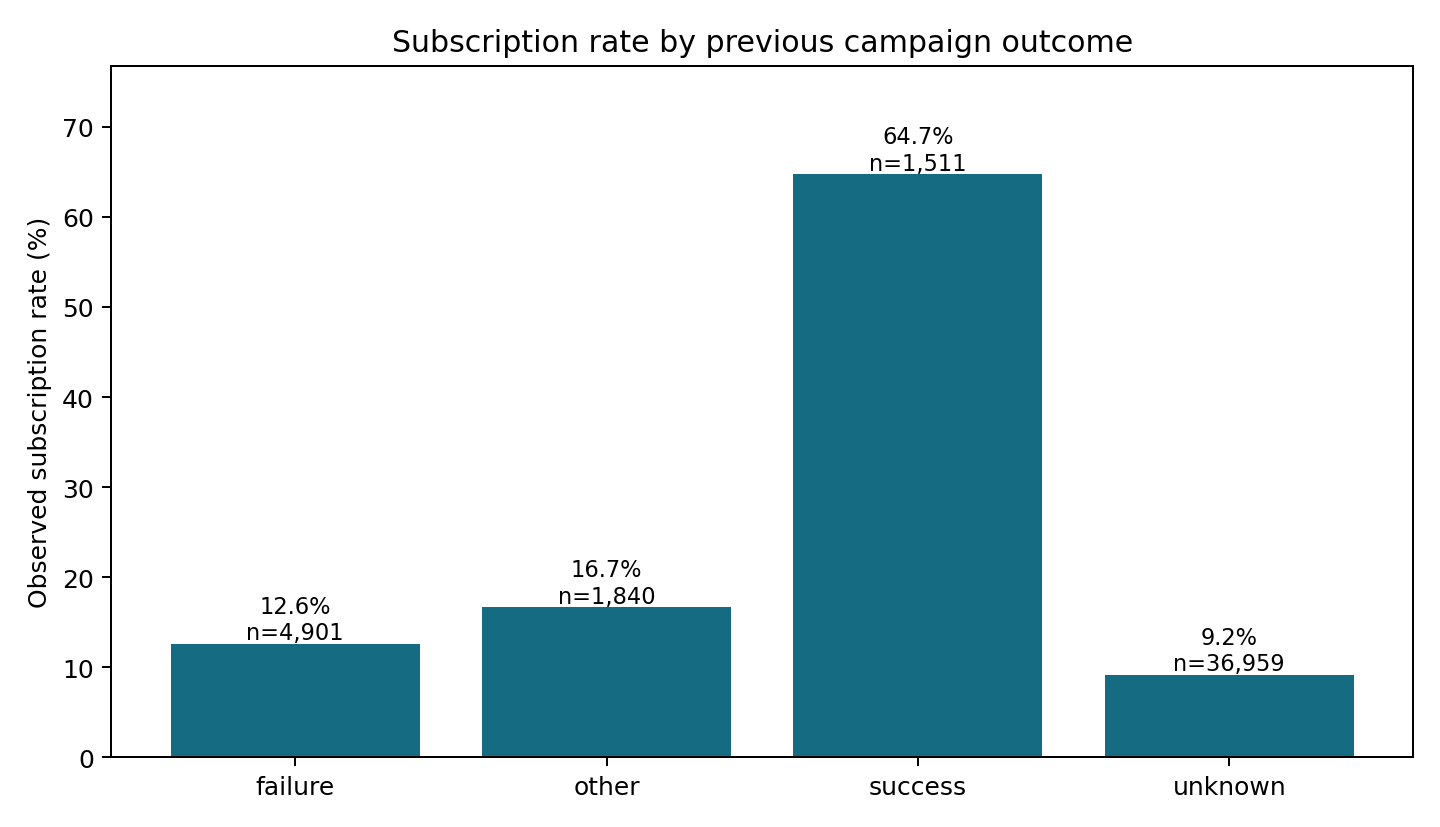

In [4]:
previous = rate_table(df, "poutcome")
display(previous)
results = run()
display(Image(filename="results/previous_outcome.png"))

**Answer:** Successful prior outcomes have 64.73% subscription (978/1,511), compared with 9.16% for unknown prior outcomes. Historical engagement appears useful for segmentation; test follow-up experimentally before claiming uplift.

## 4. Analysis: question 2
Are more current-campaign contacts associated with more subscriptions? Group into 1, 2–3, 4–5 and 6+ contacts. Counts include the final contact and may reflect difficulty converting a prospect.

,count,sum,mean
contact_band,,,
1,17544,2561,0.145976
2–3,18026,2019,0.112005
4–5,5286,456,0.086266
6+,4355,253,0.058094


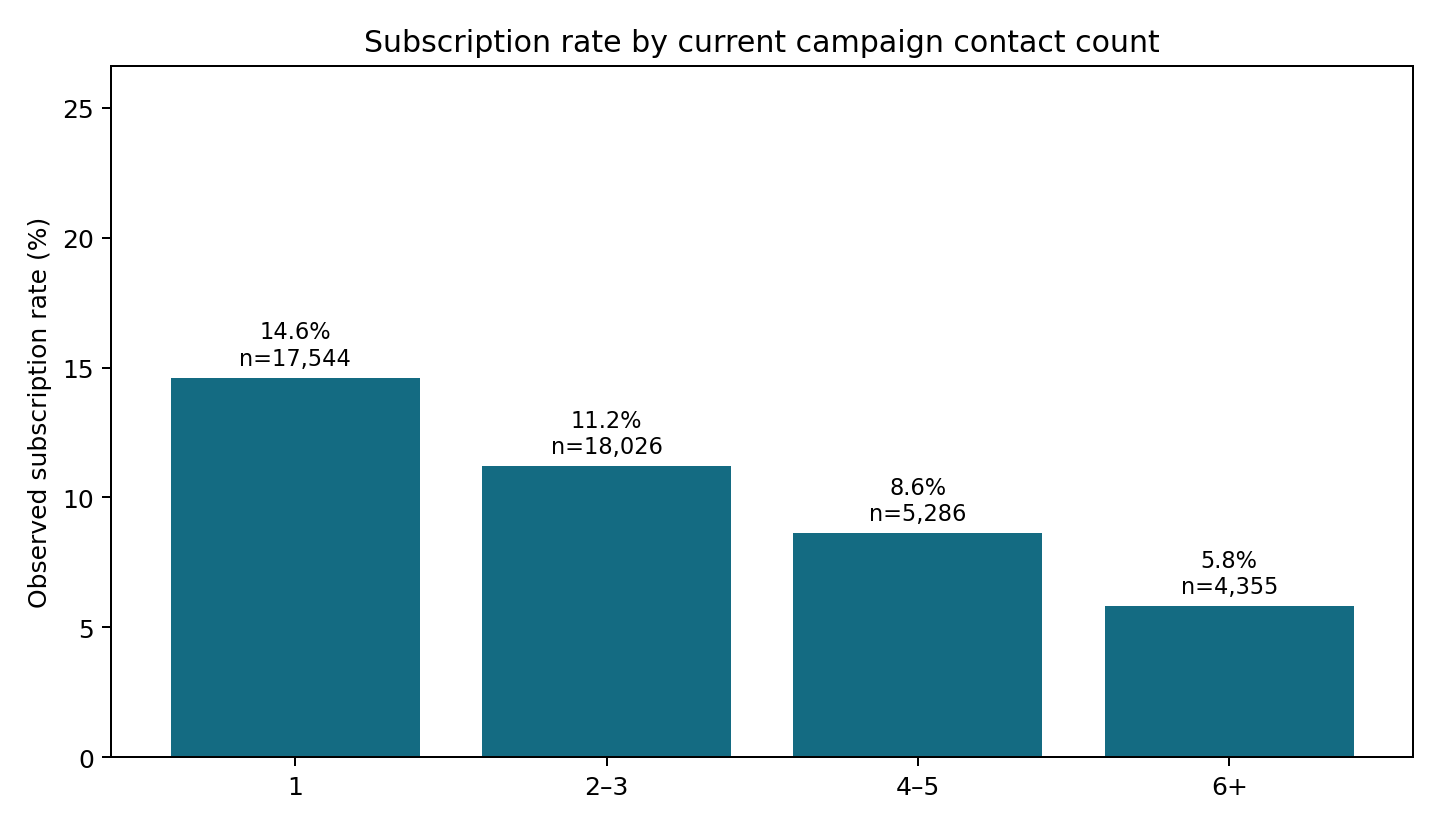

In [5]:
bands = pd.cut(df.campaign, [0,1,3,5,np.inf], labels=["1","2–3","4–5","6+"])
contacts = rate_table(df.assign(contact_band=bands), "contact_band")
display(contacts)
display(Image(filename="results/contact_frequency.png"))

**Answer:** Observed rates decline from 14.60% at one contact to 5.81% at six or more. This is an association. Successful customers may stop receiving calls early, so it does not establish that an extra call causes a lower conversion rate. Test a contact cap rather than imposing one solely from this table.

## 4. Modeling: question 3
Fit logistic regression with balanced class weights for interpretable, scalable ranking. Compare against a most-frequent DummyClassifier. No hyperparameters or thresholds are chosen using test outcomes. Report ROC AUC, average precision, threshold precision/recall and top-20% lift.

In [6]:
metrics = results["model"]
display(pd.Series(metrics).to_frame("value"))

,value
train_rows,36168
test_rows,9043
test_subscription_rate,0.315824
roc_auc,0.716226
average_precision,0.546747
precision_at_0_5,0.424823
recall_at_0_5,0.776611
top_20_percent_rows,1809
top_20_percent_subscription_rate,0.608624
top_20_percent_lift,1.927095


## 5. Evaluation
A chronological test set shows ROC AUC 0.716 and average precision 0.547. The top-scored 20% has 60.86% observed subscription versus 31.58% in the whole test set, a 1.93× observed lift. The baseline predicts no subscribers and achieves 68.42% accuracy with zero recall. At threshold 0.5 the model has 42.48% precision and 77.66% recall.

The holdout positive rate is considerably higher than the full-data rate (11.70%), revealing time-period shift. These values describe this historical holdout only. Precision at a budget cutoff does not imply incremental sales or return on investment. There is no customer identifier to test repeat-customer overlap; field availability must be verified before live use.

## 6. Deployment and communication
Publish ARTICLE.md/article.html for a nontechnical audience. Run a prospective randomized pilot comparing model-ranked queues with current practice. Verify scoring-time feature availability, current-data performance, subgroup fairness and contact permissions. Measure cost, complaints and actual incremental subscriptions. Select thresholds using capacity and economics.

The notebook is reusable through documented functions in analysis.py. Included data permit offline reproduction. Sources: https://archive.ics.uci.edu/dataset/222/bank+marketing and original data/bank-names.txt. See README.md for setup and acknowledgments.